# Basic LLM to Agent Loop

In this notebook, we'll use Python to connect two local AI models: Qwen and Flux.

**Flux** receives **text** and turns it into an **image**.<br>
**Qwen** receives **text** and replies with **text**, but it can also receive an **image** along with the text. So we can use Qwen to review whatever Flux created.

We'll combine them in a simple Python loop that keeps generating images until Qwen approves one.

## Imports

In [1]:
import torch
from diffusers import FluxPipeline
from transformers import pipeline
import warnings
warnings.filterwarnings('ignore')

## Load Models

Load Qwen and Flux from Hugging Face. Qwen uses automatic device placement (CPU or GPU), while Flux uses CPU offloading to reduce GPU memory usage.

### 💡 No GPU or limited GPU memory?

You can try smaller models:
<br>
**Qwen**: Qwen/Qwen3-VL-2B-Instruct
**Flux Klein**: black-forest-labs/FLUX.2-klein-4B
<br>
Just make sure you adjust `FluxPipeline` to `Flux2KleinPipeline` if you change the Flux model.
<br>
<br>
These models require less memory, but CPU-only execution may need additional adjustments and can be very slow.

In [2]:
qwen = pipeline(
    "image-text-to-text",
    model="Qwen/Qwen3-VL-8B-Instruct",
    device_map="auto",
    dtype=torch.bfloat16
)

flux = FluxPipeline.from_pretrained(
    "black-forest-labs/FLUX.1-schnell",
    dtype=torch.bfloat16
)

flux.enable_sequential_cpu_offload()

Loading weights:   0%|          | 0/750 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/219 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

## 🧠 Guided Decision 1: Describe the Photo

We'll give Qwen a **mood** and a **list of locations**. Qwen will choose the best location for the mood and generate a one-sentence description of Butters' photo.<br>
Python controls the available options, while Qwen makes the decision.

In [7]:
mode = "cinematic"
locations = ["beach", "park", "living room"]

prompt = f"""
Butters is a grey cat who feels {mode} today.

Choose the best location for his Instagram photo:
{locations}

Reply with one sentence describing the photo.
"""
description = qwen(prompt, return_full_text=False)[0]['generated_text']
description

[transformers] Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


'Butters, the grey cat, lounges dramatically on a sunlit park bench, cinematic rays filtering through autumn leaves as he stares into the distance with intense, movie-star-worthy focus.'

## ✨ AI Generation 1: Generate The Image 

Now that Qwen has described the photo, we can pass that description to Flux.
Flux will generate a new image based on Qwen's output.

💡 Tip: You can adjust the optional parameters below to generate smaller images faster. We're using a resolution of 512×512 and 4 inference steps to reduce generation time.

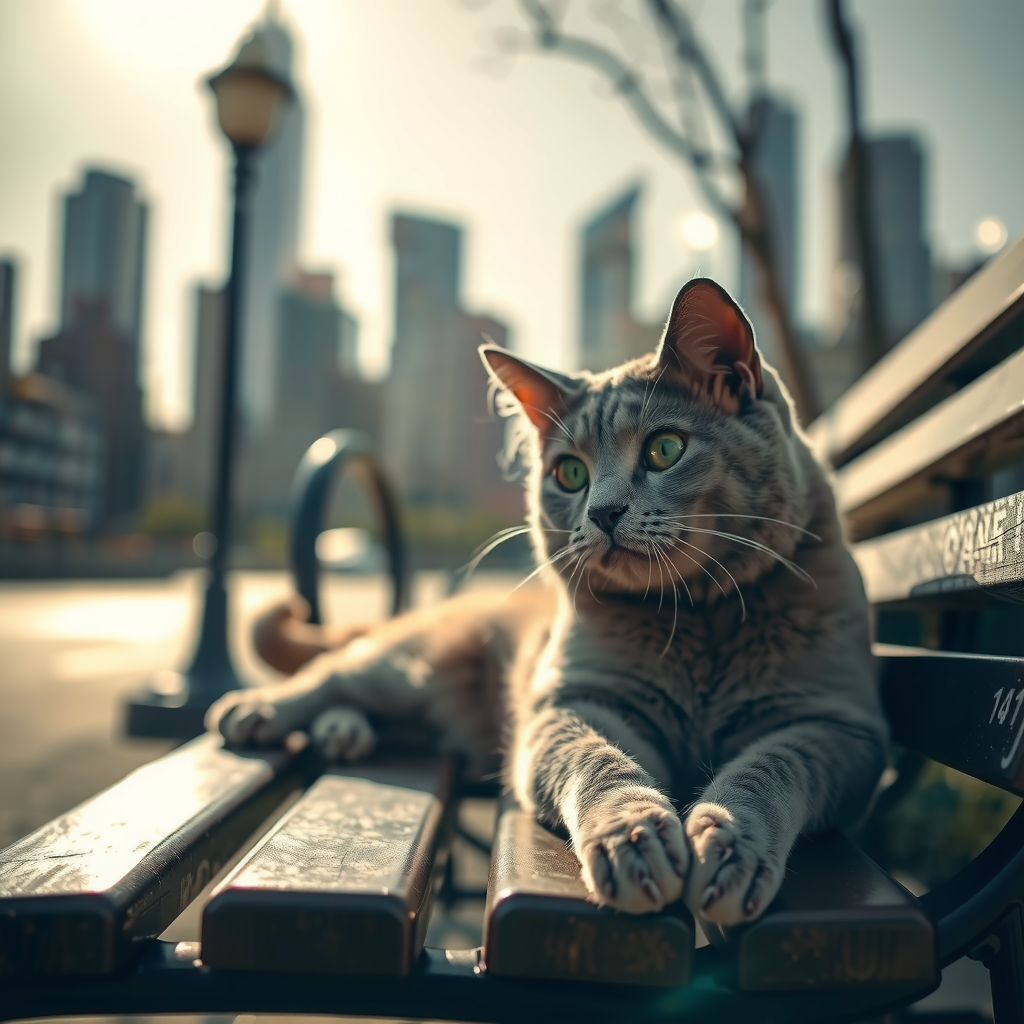

In [8]:
image = flux(
    description,
    # optional parameters: for a smaller image, generated faster
    height=512,
    width=512,
    num_inference_steps=4,
    guidance_scale=0.0
)
image.images[0]

## 🧠 AI Decision 2: Evaluate the Image

Now we will send the generated image back to Qwen and ask if it looks believable and realistic.

This time, Qwen receives both an image and text. It will review the image for obvious AI mistakes and reply with either **YES** or **NO**.

In [14]:
image_prompt = [{
    "role": "user",
    "content": [
        {"type": "image", "image": image.images[0]},
        {"type": "text", "text": """
            Does this image look believable and realistic?
            Check for obvious AI mistakes or strange anatomy. 
            Reply YES or NO.
        """}
    ]
}]

qwen(image_prompt, return_full_text=False)[0]['generated_text']

[transformers] Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


'NO'

## 🐍 Python Loop: Connect Everything Together

Now we'll combine all three operations into a single workflow:

- 🐍 **Python Logic:** Controls the sequence of operations.
- 🧠 **AI Decisions:** Qwen describes the photo and evaluates the generated image.
- ✨ **AI Generation:** Flux generates the image.

We'll also load our first prompt from a separate Markdown file (`prompt.md`) and insert the Python variables using `.format()`.

The `while` loop keeps generating and evaluating images until Qwen replies **YES**. Once the image is approved, Python breaks the loop and displays the final result.

[transformers] Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  
Butters is lounging on a sun-warmed blanket in the park, tail curled around a tiny bouquet of wildflowers, eyes dreamy as he gazes into the distance—romantic vibes with a feline twist.

**Best location: park**


  0%|          | 0/4 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  0%|          | 0/4 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  0%|          | 0/4 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  0%|          | 0/4 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


photo looks real


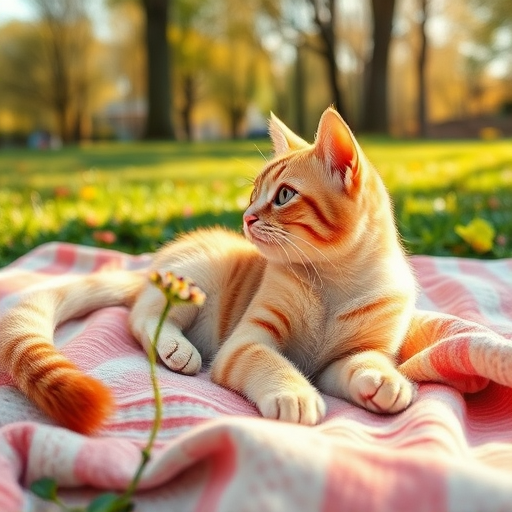

In [8]:
mode = "romantic"
locations = ["office", "beach", "park", "living room", "kitchen"]

prompt = open("quickstart_prompt.md").read().format(
    mode=mode,
    locations=locations
)

description = qwen(prompt, return_full_text=False)[0]["generated_text"]
print(description)

while True:
    image = flux(
        description,
        # optional parameters: for a smaller image, generated faster
        height=512,
        width=512,
        num_inference_steps=4,
        guidance_scale=0.0
    )

    image_prompt = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image.images[0]},
            {"type": "text", "text": """
                Does this image look believable and realistic?
                Check for obvious AI mistakes or strange anatomy. 
                Reply YES or NO.
            """}
        ]
    }]
        
    decision = qwen(image_prompt, return_full_text=False)[0]["generated_text"]

    if decision.strip().upper() == "YES":
        print("photo looks real")
        break

image.images[0]

## 🐈 Final Results

Our loop worked! **Flux generated 4 images before Qwen finally approved one!** 🎉
But there's one little problem... **Butters is supposed to be a grey cat!! not orange!** 😅

Why did this happen? Because we focused on making the image look realistic, but never asked Qwen to check if the cat actually looks like Butters. We also didn't provide enough details to preserve his appearance across multiple generations.

To fix this, we could use more detailed prompts, provide reference images, or add another AI decision to check the cat's appearance.

But this is just a QuickStart! Our goal was to demonstrate how **Python logic, AI decisions, and AI generation** can work together in a simple loop.
<br>
And that's exactly what we built! 🚀